# ATP Conformer Analysis

Downloads all ATP-containing structures from the PDB, extracts conformers, filters
incomplete molecules, aligns to a reference, clusters by RMSD (Butina), and exports
representative SDF files.

---

**Checkpointing.** Each slow step saves its output to disk. Re-running a cell will
load from disk if the file already exists — delete the file to force recomputation.

| Step | Checkpoint file | Approx. time |
|---|---|---|
| Download + extract | `atp_conformers_raw.sdf` | 20–40 min (first run) |
| RMSD matrix | `rmsd_matrix_filtered.npy` | 2–6 h for ~8 k structures |
| 2D embedding | `embedding_mds.npy` | 5–10 min |

> **Existing data?** If you already have `rmsd_matrix.npy` (computed on unfiltered
> molecules), the RMSD cell will sub-index it automatically and save
> `rmsd_matrix_filtered.npy` — no recomputation needed.

In [1]:
# ─── Parameters — edit before running ─────────────────────────────────────────
OUTPUT_DIR   = 'output'      # data output directory
PLOT_DIR     = 'pictures'    # PNG plots
CUTOFF_A     = 1.5    # Butina RMSD clustering cutoff (Ångström)
N_REPS       = 10     # representative conformers written per cluster SDF
MAX_STRUCTS  = 9999   # cap on PDB structures fetched (9999 = all)
SEED         = 42     # random seed
TEST_MODE    = False  # True = 50 synthetic conformers (quick smoke-test)
SMALL_THRESHOLD = 10  # clusters below this size are grouped as 'small' in plots

In [2]:
%matplotlib inline
import os, json, time, random
from collections import defaultdict, Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import requests
from scipy.sparse.linalg import LinearOperator, eigsh

from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign, rdFMCS
from rdkit.ML.Cluster import Butina

random.seed(SEED)
Path(OUTPUT_DIR).mkdir(exist_ok=True)
Path(PLOT_DIR).mkdir(exist_ok=True)

ATP_SMILES  = ('c1nc(c2c(n1)n(cn2)[C@@H]3[C@@H]([C@@H]([C@H]'
               '(O3)COP(=O)(O)OP(=O)(O)OP(=O)(O)O)O)O)N')
EXPECTED_HA = Chem.MolFromSmiles(ATP_SMILES).GetNumHeavyAtoms()
print(f'Setup OK  |  expected ATP heavy atoms: {EXPECTED_HA}')

Setup OK  |  expected ATP heavy atoms: 31


## Helper functions
Run this cell once — functions are used in all steps below.

In [3]:
def get_atp_pdb_ids(max_results=9999):
    url = 'https://www.ebi.ac.uk/pdbe/api/pdb/compound/in_pdb/ATP'
    resp = requests.get(url, timeout=60)
    resp.raise_for_status()
    atp_data = resp.json().get('ATP', [])
    ids = []
    for item in atp_data:
        if isinstance(item, str):
            ids.append(item.upper())
        elif isinstance(item, dict):
            for key in ('pdb_id', 'entry_id', 'id', 'pdbId'):
                if key in item:
                    ids.append(item[key].upper())
                    break
    return ids[:max_results]


def download_pdb(pdb_id, cache_dir='pdb_cache'):
    os.makedirs(cache_dir, exist_ok=True)
    local = Path(cache_dir) / f'{pdb_id.lower()}.pdb'
    if local.exists():
        return local.read_text()
    resp = requests.get(f'https://files.rcsb.org/download/{pdb_id}.pdb', timeout=30)
    if resp.status_code == 200:
        local.write_text(resp.text)
        return resp.text
    return None


def extract_atp_from_pdb_text(pdb_text, pdb_id):
    atp_lines = [l for l in pdb_text.split('\n')
                 if (l.startswith('HETATM') and l[17:20].strip() == 'ATP')
                 or l.startswith('CONECT') or l.startswith('END')]
    if not atp_lines:
        return []
    groups = defaultdict(list)
    for l in atp_lines:
        if l.startswith('HETATM'):
            groups[f'{l[21]}_{l[22:26].strip()}'].append(l)
    mols = []
    for key, lines in groups.items():
        mol = Chem.MolFromPDBBlock('\n'.join(lines + ['END']),
                                   sanitize=False, removeHs=False)
        if mol and mol.GetNumAtoms() > 5:
            try:
                Chem.SanitizeMol(mol)
                mol.SetProp('_Name', f'{pdb_id}_{key}')
                mols.append(mol)
            except Exception:
                pass
    return mols


def compute_rmsd_matrix(mols):
    N = len(mols)
    mat = np.zeros((N, N))
    for i in range(N):
        if i % 100 == 0:
            print(f'  row {i}/{N}', end='\r')
        for j in range(i+1, N):
            try:
                rms = rdMolAlign.GetBestRMS(mols[i], mols[j])
            except Exception:
                rms = 99.0
            mat[i, j] = mat[j, i] = rms
    print()
    return mat


def cluster_butina(rmsd_matrix, cutoff):
    N = rmsd_matrix.shape[0]
    dist_list = [float(rmsd_matrix[i, j]) for i in range(1, N) for j in range(i)]
    clusters = Butina.ClusterData(dist_list, N, cutoff, isDistData=True, reordering=True)
    return sorted(clusters, key=len, reverse=True)


def build_reference_atp():
    mol = Chem.MolFromSmiles(ATP_SMILES)
    mol = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol, randomSeed=42)
    AllChem.MMFFOptimizeMolecule(mol)
    return Chem.RemoveHs(mol)


def make_alignment_pattern(ref_mol, probe_mol):
    mcs = rdFMCS.FindMCS(
        [probe_mol, ref_mol],
        atomCompare=rdFMCS.AtomCompare.CompareElements,
        bondCompare=rdFMCS.BondCompare.CompareAny,
        timeout=10,
    )
    pattern   = Chem.MolFromSmarts(mcs.smartsString)
    ref_match = ref_mol.GetSubstructMatch(pattern)
    return pattern, ref_match


def align_mol(mol, ref_mol, pattern, ref_match):
    probe_match = mol.GetSubstructMatch(pattern)
    if not probe_match or not ref_match:
        return False
    try:
        rdMolAlign.AlignMol(mol, ref_mol, atomMap=list(zip(probe_match, ref_match)))
        return True
    except Exception:
        return False


def mds_embedding(rmsd_mat, cache_path):
    cache_path = Path(cache_path)
    if cache_path.exists():
        print(f'  Loading cached embedding from {cache_path}')
        return np.load(cache_path)
    print('  Computing classical MDS (PCoA) — takes 5-10 min for ~8 k points...')
    D2 = rmsd_mat.astype(np.float32) ** 2
    n  = D2.shape[0]
    def matvec(v):
        w  = v - v.mean()
        Bv = D2 @ w.astype(np.float32)
        Bv -= Bv.mean()
        return -0.5 * Bv.astype(np.float64)
    B_op = LinearOperator((n, n), matvec=matvec, dtype=np.float64)
    vals, vecs = eigsh(B_op, k=2, which='LM', tol=1e-4, maxiter=500)
    order = np.argsort(vals)[::-1]
    embedding = vecs[:, order] * np.sqrt(np.maximum(vals[order], 0))
    np.save(cache_path, embedding)
    print(f'  Saved to {cache_path}')
    return embedding


print('Helper functions loaded.')

Helper functions loaded.


---
## Step 1 — Fetch ATP-containing PDB IDs
Queries the PDBe REST API for all structures that contain the ligand ATP.
In test mode, this step is skipped and 50 synthetic conformers are generated instead.

In [4]:
if TEST_MODE:
    pdb_ids = []
    print('TEST MODE — will generate 50 synthetic conformers, skipping PDB download.')
else:
    print('Fetching ATP PDB IDs from PDBe...')
    pdb_ids = get_atp_pdb_ids(MAX_STRUCTS)
    print(f'  {len(pdb_ids)} structures found.')

Fetching ATP PDB IDs from PDBe...
  3627 structures found.


---
## Step 2 — Download & Extract ATP Conformers
Downloads each PDB file (cached locally in `pdb_cache/`) and extracts all ATP
HETATM records. Structures with multiple ATP copies contribute one molecule each.

**Checkpoint:** result is saved to `atp_conformers_raw.sdf` and reloaded on
subsequent runs — no re-downloading needed.

In [5]:
RAW_SDF = f'{OUTPUT_DIR}/atp_conformers_raw.sdf'

if TEST_MODE:
    mol_h = Chem.AddHs(Chem.MolFromSmiles(ATP_SMILES))
    cids  = AllChem.EmbedMultipleConfs(mol_h, numConfs=50, randomSeed=SEED)
    mols  = []
    for cid in cids:
        m = Chem.RWMol(mol_h)
        m.SetProp('_Name', f'synthetic_{cid}')
        mols.append(m.GetMol())
    print(f'Generated {len(mols)} synthetic conformers.')

elif Path(RAW_SDF).exists():
    print(f'Loading from checkpoint: {RAW_SDF}')
    mols = [m for m in Chem.SDMolSupplier(RAW_SDF, removeHs=False) if m]
    print(f'  Loaded {len(mols):,} molecules.')

else:
    print(f'Extracting ATP from {len(pdb_ids)} PDB structures...')
    mols = []
    for i, pdb_id in enumerate(pdb_ids):
        if i % 200 == 0:
            print(f'  {i}/{len(pdb_ids)} processed  |  {len(mols)} molecules so far')
        pdb_text = download_pdb(pdb_id)
        if pdb_text:
            mols.extend(extract_atp_from_pdb_text(pdb_text, pdb_id))
        time.sleep(0.05)  # be polite to RCSB
    print(f'\n  Extracted {len(mols):,} ATP conformers from {len(pdb_ids)} structures.')
    print(f'  Saving checkpoint to {RAW_SDF}...')
    with Chem.SDWriter(RAW_SDF) as w:
        w.SetKekulize(False)
        for mol in mols:
            w.write(mol)
    print('  Done.')

print(f'\nTotal conformers available: {len(mols):,}')

Loading from checkpoint: output/atp_conformers_raw.sdf
  Loaded 8,793 molecules.

Total conformers available: 8,793


---
## Step 3 — Filter Incomplete Molecules & Align to Reference

**Filter:** keep only conformers with exactly the expected number of heavy atoms (31
for ATP). Incomplete records from the PDB — missing phosphate oxygens, truncated
adenine, etc. — are discarded.

**Align:** all surviving molecules are superposed onto an MMFF-optimised ATP reference
using the maximum common substructure (MCS). This puts every conformer in the same
coordinate frame for visual comparison.

In [6]:
# ── Filter ──────────────────────────────────────────────────────────────────
filtered_indices = [i for i, m in enumerate(mols) if m.GetNumHeavyAtoms() == EXPECTED_HA]
mols_filtered    = [mols[i] for i in filtered_indices]

n_excl = len(mols) - len(mols_filtered)
print(f'Heavy atom filter ({EXPECTED_HA} expected):')
print(f'  Kept:     {len(mols_filtered):,}')
print(f'  Excluded: {n_excl:,} ({n_excl/len(mols)*100:.1f}%)')

excl_counts = Counter(mols[i].GetNumHeavyAtoms()
                      for i in range(len(mols)) if i not in set(filtered_indices))
print(f'  HA distribution of excluded: {dict(sorted(excl_counts.items()))}')

# ── Align ───────────────────────────────────────────────────────────────────
print('\nAligning to reference ATP...')
ref_mol = build_reference_atp()
pattern, ref_match = make_alignment_pattern(ref_mol, mols_filtered[0])
print(f'  MCS: {pattern.GetNumAtoms()} atoms, {pattern.GetNumBonds()} bonds')

n_aligned = sum(align_mol(m, ref_mol, pattern, ref_match) for m in mols_filtered)
print(f'  Aligned: {n_aligned}/{len(mols_filtered)}')
if n_aligned < len(mols_filtered):
    print(f'  ({len(mols_filtered)-n_aligned} molecules could not be aligned — kept unaligned)')

Heavy atom filter (31 expected):
  Kept:     8,793
  Excluded: 0 (0.0%)
  HA distribution of excluded: {}

Aligning to reference ATP...
  MCS: 31 atoms, 33 bonds
  Aligned: 8791/8793
  (2 molecules could not be aligned — kept unaligned)


---
## Step 4 — Pairwise RMSD Matrix

Computes all-vs-all heavy-atom RMSD after optimal superposition (`GetBestRMS`).
This is the most expensive step: O(N²) pairwise alignments.

**Checkpoint logic (automatic):**
1. If `rmsd_matrix_filtered.npy` exists with the right shape → load it.
2. Else if `rmsd_matrix.npy` exists (older unfiltered run) → sub-index to the filtered
   molecules and save as `rmsd_matrix_filtered.npy`.
3. Otherwise → compute from scratch (hours) and save.

In [7]:
N = len(mols_filtered)
RMSD_FILTERED = f'{OUTPUT_DIR}/rmsd_matrix_filtered.npy'
RMSD_FULL     = f'{OUTPUT_DIR}/rmsd_matrix.npy'

if Path(RMSD_FILTERED).exists():
    rmsd_mat = np.load(RMSD_FILTERED)
    assert rmsd_mat.shape == (N, N), (
        f'Shape mismatch: matrix is {rmsd_mat.shape} but expected ({N}, {N}). '
        f'Delete {RMSD_FILTERED} to recompute.')
    print(f'Loaded filtered RMSD matrix from {RMSD_FILTERED}  ({rmsd_mat.shape})')

elif Path(RMSD_FULL).exists():
    rmsd_full = np.load(RMSD_FULL)
    if rmsd_full.shape == (N, N):
        rmsd_mat = rmsd_full
        print(f'Loaded RMSD matrix from {RMSD_FULL}  ({rmsd_mat.shape})')
    else:
        print(f'Found {rmsd_full.shape} matrix — sub-indexing to ({N}, {N}) filtered molecules...')
        idx = np.array(filtered_indices)
        rmsd_mat = rmsd_full[np.ix_(idx, idx)]
        np.save(RMSD_FILTERED, rmsd_mat)
        print(f'  Saved sub-indexed matrix to {RMSD_FILTERED}')

else:
    print(f'Computing {N}x{N} RMSD matrix from scratch...')
    print('  Warning: this can take several hours for thousands of molecules.')
    rmsd_mat = compute_rmsd_matrix(mols_filtered)
    np.save(RMSD_FILTERED, rmsd_mat)
    print(f'  Saved to {RMSD_FILTERED}')

print(f'RMSD matrix shape: {rmsd_mat.shape}  |  max RMSD: {rmsd_mat.max():.2f} Å')

Loaded filtered RMSD matrix from output/rmsd_matrix_filtered.npy  ((8793, 8793))
RMSD matrix shape: (8793, 8793)  |  max RMSD: 99.00 Å


---
## Step 5 — Cluster with Butina Algorithm

Butina clustering groups conformers such that every cluster member is within
`CUTOFF_A` Å RMSD of the cluster centroid. Clusters are sorted by size (largest first).

In [8]:
print(f'Clustering {N} conformers at {CUTOFF_A} Å cutoff...')
clusters = cluster_butina(rmsd_mat, CUTOFF_A)
print(f'  {len(clusters)} clusters found')
print(f'  Largest cluster: {len(clusters[0]):,} ({len(clusters[0])/N*100:.1f}%)')
print()

# Summary table for the 10 biggest clusters
print(f'{"Rank":>4}  {"Size":>6}  {"% total":>8}  Centroid name')
print('-' * 55)
for i, cl in enumerate(clusters[:10]):
    centroid = mols_filtered[cl[0]]
    name = centroid.GetProp('_Name') if centroid.HasProp('_Name') else str(cl[0])
    print(f'{i+1:>4}  {len(cl):>6,}  {len(cl)/N*100:>7.1f}%  {name}')

Clustering 8793 conformers at 1.5 Å cutoff...
  82 clusters found
  Largest cluster: 4,871 (55.4%)

Rank    Size   % total  Centroid name
-------------------------------------------------------
   1   4,871     55.4%  6RDR_T_1001
   2     944     10.7%  5FWP_B_1692
   3     576      6.6%  9VLN_4_902
   4     520      5.9%  4EAH_F_403
   5     447      5.1%  1KH2_B_1510
   6     317      3.6%  7Y59_A_901
   7     188      2.1%  8V48_A_501
   8     133      1.5%  3RGL_A_401
   9     108      1.2%  8DTB_A_5103
  10      84      1.0%  8PPD_B_505


---
## Step 6 — Cluster Size Distribution

Bar chart of conformers per cluster. Clusters with fewer than `SMALL_THRESHOLD`
members are aggregated into a single 'small clusters' bar.

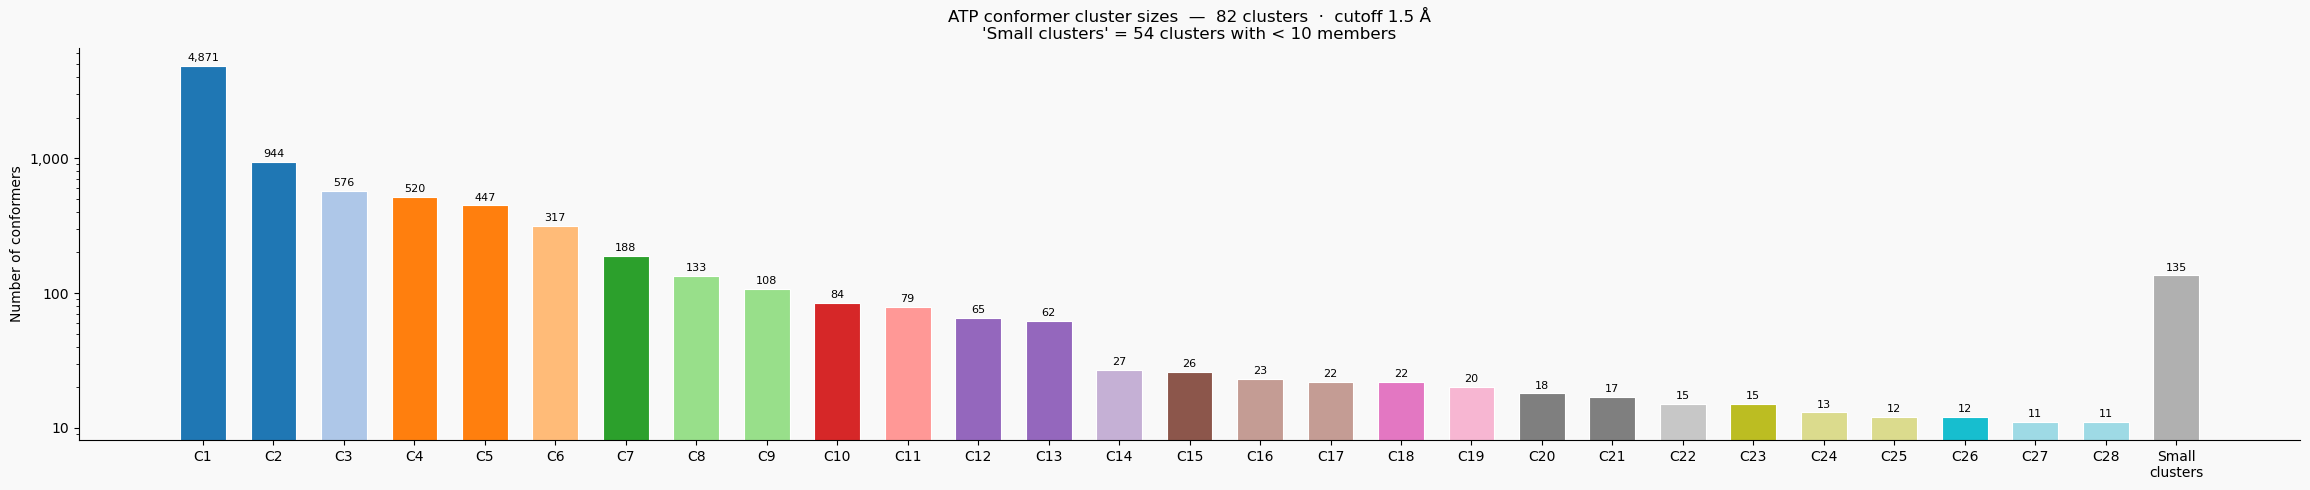

In [9]:
sizes     = [len(cl) for cl in clusters]
big_bars  = [(i+1, s) for i, s in enumerate(sizes) if s >= SMALL_THRESHOLD]
small_tot = sum(s for s in sizes if s < SMALL_THRESHOLD)
n_small   = sum(1 for s in sizes if s < SMALL_THRESHOLD)

n_big  = len(big_bars)
cmap   = plt.get_cmap('tab10' if n_big <= 10 else 'tab20')
labels = [f'C{r}' for r, _ in big_bars] + ['Small\nclusters']
values = [s for _, s in big_bars] + [small_tot]
colors = [cmap(i / max(n_big-1, 1)) for i in range(n_big)] + ['#b0b0b0']

fig, ax = plt.subplots(figsize=(max(8, len(labels)*0.8), 5))
fig.patch.set_facecolor('#f9f9f9'); ax.set_facecolor('#f9f9f9')
bars = ax.bar(labels, values, color=colors, edgecolor='white', linewidth=0.8, width=0.65)
for bar, val in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.05,
            f'{val:,}', ha='center', va='bottom', fontsize=8)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_ylabel('Number of conformers')
ax.set_title(
    f'ATP conformer cluster sizes  —  {len(clusters)} clusters  ·  cutoff {CUTOFF_A} Å\n'
    f"'Small clusters' = {n_small} clusters with < {SMALL_THRESHOLD} members"
)
for spine in ['top','right']: ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/cluster_sizes_bar.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 7 — 2D Cluster Embedding (Classical MDS)

Projects all conformers into 2D using Principal Coordinates Analysis (PCoA /
classical MDS) on the RMSD matrix. Points that are close in RMSD appear close in
the plot. Axes have no direct physical meaning — they just maximise spread.

**Checkpoint:** the 2D coordinates are cached in `embedding_mds.npy`.

  Computing classical MDS (PCoA) — takes 5-10 min for ~8 k points...
  Saved to output/embedding_mds.npy


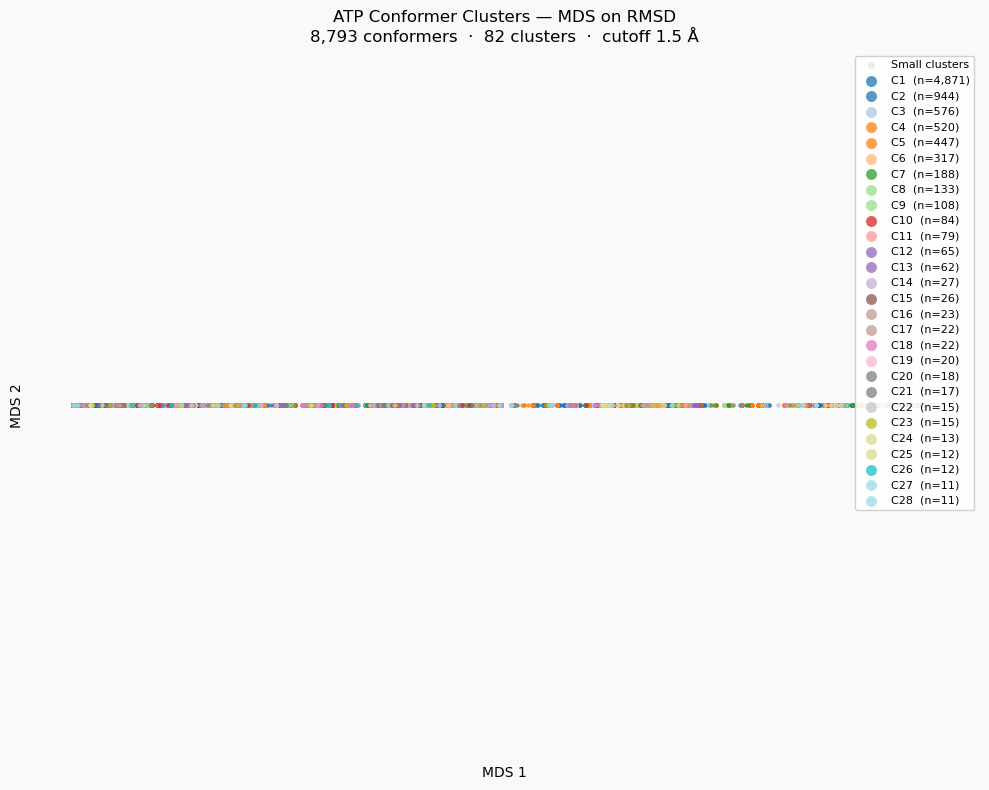

In [10]:
embedding = mds_embedding(rmsd_mat, f'{OUTPUT_DIR}/embedding_mds.npy')

# Assign cluster labels
labels_arr = np.full(N, -1, dtype=int)
for ci, cl in enumerate(clusters):
    for idx in cl:
        labels_arr[idx] = ci
big_indices = [i for i, cl in enumerate(clusters) if len(cl) >= SMALL_THRESHOLD]

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('#f9f9f9'); ax.set_facecolor('#f9f9f9')

small_mask = ~np.isin(labels_arr, big_indices)
ax.scatter(embedding[small_mask, 0], embedding[small_mask, 1],
           c='#b0b0b0', s=4, alpha=0.25, linewidths=0,
           label='Small clusters', rasterized=True)

for rank_i, ci in enumerate(big_indices):
    mask  = labels_arr == ci
    color = cmap(rank_i / max(len(big_indices)-1, 1))
    ax.scatter(embedding[mask, 0], embedding[mask, 1],
               c=[color], s=10, alpha=0.75, linewidths=0,
               label=f'C{rank_i+1}  (n={len(clusters[ci]):,})',
               rasterized=True)

ax.set_title(
    f'ATP Conformer Clusters — MDS on RMSD\n'
    f'{N:,} conformers  ·  {len(clusters)} clusters  ·  cutoff {CUTOFF_A} Å'
)
ax.set_xlabel('MDS 1'); ax.set_ylabel('MDS 2')
ax.legend(fontsize=8, markerscale=2.5, loc='upper right', framealpha=0.9)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/cluster_embedding_mds.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 8 — Exclusion Plot (Filter Quality)

Shows how many molecules were excluded by the heavy-atom filter in each cluster.
Clusters dominated by incomplete structures are likely artefacts.

In [11]:
# Rebuild full cluster assignments on *unfiltered* mols for the exclusion plot
# (re-use the unfiltered RMSD matrix if available, otherwise skip this cell)
RMSD_FULL = f'{OUTPUT_DIR}/rmsd_matrix.npy'

if not Path(RMSD_FULL).exists():
    print('Skipping exclusion plot — unfiltered rmsd_matrix.npy not found.')
else:
    rmsd_full = np.load(RMSD_FULL)
    N_full = rmsd_full.shape[0]
    dist_full = [float(rmsd_full[i,j]) for i in range(1, N_full) for j in range(i)]
    clusters_full = Butina.ClusterData(dist_full, N_full, CUTOFF_A,
                                       isDistData=True, reordering=True)
    clusters_full = sorted(clusters_full, key=len, reverse=True)

    full_ha = np.array([mols[i].GetNumHeavyAtoms() for i in range(N_full)])
    passes_full = full_ha == EXPECTED_HA

    stats = [{'rank': ci+1, 'total': len(cl),
               'excl': sum(1 for idx in cl if not passes_full[idx]),
               'kept': sum(1 for idx in cl if passes_full[idx])}
             for ci, cl in enumerate(clusters_full)]

    big_s  = [s for s in stats if s['total'] >= SMALL_THRESHOLD]
    sm_agg = {'rank':'sm', 'total': sum(s['total'] for s in stats if s['total']<SMALL_THRESHOLD),
               'excl': sum(s['excl'] for s in stats if s['total']<SMALL_THRESHOLD),
               'kept': sum(s['kept'] for s in stats if s['total']<SMALL_THRESHOLD)}
    pd_ = big_s + [sm_agg]
    xl  = [f'C{s["rank"]}' for s in big_s] + ['Small\nclusters']

    fig, ax = plt.subplots(figsize=(max(8, len(xl)*0.85), 5))
    fig.patch.set_facecolor('#f9f9f9'); ax.set_facecolor('#f9f9f9')
    x = list(range(len(xl)))
    ax.bar(x, [s['kept'] for s in pd_], label='Complete',
           color='#4878d0', edgecolor='white', linewidth=0.8, width=0.65)
    ax.bar(x, [s['excl'] for s in pd_], bottom=[s['kept'] for s in pd_],
           label=f'Excluded (\u2260{EXPECTED_HA} heavy atoms)',
           color='#ee854a', edgecolor='white', linewidth=0.8, width=0.65)
    for xi, s in enumerate(pd_):
        if s['excl'] > 0:
            ax.text(xi, s['kept']+s['excl']*1.05, str(s['excl']),
                    ha='center', va='bottom', fontsize=8,
                    color='#cc5500', fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(xl)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylabel('Number of conformers')
    ax.set_title(
        f'Incomplete ATP conformers per cluster  —  '
        f'{(~passes_full).sum():,} of {N_full:,} excluded'
    )
    ax.legend(fontsize=9)
    for spine in ['top','right']: ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.savefig(f'{PLOT_DIR}/cluster_filter_exclusions.png', dpi=150, bbox_inches='tight')
    plt.show()

Skipping exclusion plot — unfiltered rmsd_matrix.npy not found.


---
## Step 9 — Export Cluster Representative SDFs

For each cluster, writes up to `N_REPS` conformers to an SDF file in
`cluster_representatives/`. The first molecule in every file is always the
cluster centroid; the rest are randomly sampled. All molecules are filtered
(complete heavy atoms) and aligned to the reference.

In [12]:
out_dir = Path(OUTPUT_DIR) / 'cluster_representatives'
out_dir.mkdir(exist_ok=True)

for ci, cl in enumerate(clusters):
    rank     = ci + 1
    n_sample = min(N_REPS, len(cl))
    centroid = cl[0]
    rest     = list(cl[1:])
    random.shuffle(rest)
    sampled  = [centroid] + rest[:n_sample - 1]

    sdf_path = out_dir / f'cluster_{rank:02d}_representatives.sdf'
    with Chem.SDWriter(str(sdf_path)) as w:
        w.SetKekulize(False)
        for pos, idx in enumerate(sampled):
            mol = mols_filtered[idx]
            mol.SetProp('Cluster_Rank',  str(rank))
            mol.SetProp('Cluster_Size',  str(len(cl)))
            mol.SetProp('Is_Centroid',   '1' if pos == 0 else '0')
            mol.SetProp('Conformer_Index', str(idx))
            w.write(mol)

    print(f'  cluster_{rank:02d}:  {n_sample} reps  (cluster size {len(cl):,})')

print(f'\nDone — {len(clusters)} SDF files written to {out_dir}/')

  cluster_01:  10 reps  (cluster size 4,871)
  cluster_02:  10 reps  (cluster size 944)
  cluster_03:  10 reps  (cluster size 576)
  cluster_04:  10 reps  (cluster size 520)
  cluster_05:  10 reps  (cluster size 447)
  cluster_06:  10 reps  (cluster size 317)
  cluster_07:  10 reps  (cluster size 188)
  cluster_08:  10 reps  (cluster size 133)
  cluster_09:  10 reps  (cluster size 108)
  cluster_10:  10 reps  (cluster size 84)
  cluster_11:  10 reps  (cluster size 79)
  cluster_12:  10 reps  (cluster size 65)
  cluster_13:  10 reps  (cluster size 62)
  cluster_14:  10 reps  (cluster size 27)
  cluster_15:  10 reps  (cluster size 26)
  cluster_16:  10 reps  (cluster size 23)
  cluster_17:  10 reps  (cluster size 22)
  cluster_18:  10 reps  (cluster size 22)
  cluster_19:  10 reps  (cluster size 20)
  cluster_20:  10 reps  (cluster size 18)
  cluster_21:  10 reps  (cluster size 17)
  cluster_22:  10 reps  (cluster size 15)
  cluster_23:  10 reps  (cluster size 15)
  cluster_24:  10 reps 

---
## Step 10 — Energy-Minimised Representative per Cluster

For each cluster, every member (up to `MINIMISE_CAP` for large clusters) is
energy-minimised with **MMFF94** (RDKit). The conformer with the lowest post-
minimisation energy becomes the cluster's canonical representative.

**Why MMFF94?**  
All cluster members are the same molecule in similar geometries, so *relative*
MMFF94 energies reliably identify the least-strained local minimum within each
basin. If you need cross-cluster energy comparisons or better phosphate
treatment, re-run minimisation with GFN2-xTB (`xtb-python`) — the SDF output
format here is compatible.

**Checkpoint:** results saved to `cluster_minimised/` — delete to recompute.

**Output SDF properties per molecule:**
- `MMFF94_Energy_kcal_mol` — post-minimisation energy
- `MMFF94_Status` — `0` = converged, `1` = not fully converged, `-1` = failed
- `Is_EnergyMin_Rep` — `1` for the lowest-energy conformer in its cluster
- `Cluster_Rank`, `Cluster_Size`, `Conformer_Index` (carried over)


In [17]:
# ── Parameters ──────────────────────────────────────────────────────────────
MINIMISE_CAP  = None   # max members to minimise per cluster (None = all)
MMFF_MAX_ITER = 1000  # MMFF94 iteration cap

# ── Helper ──────────────────────────────────────────────────────────────────
# PDB-extracted molecules carry no bond orders; assign from SMILES template
# so MMFF94 can type atoms correctly (phosphate P=O, aromatic rings, etc.)
_ATP_TEMPLATE = Chem.MolFromSmiles(ATP_SMILES)

def minimise_mmff94(mol, max_iters=MMFF_MAX_ITER):
    """Return (minimised heavy-atom mol, energy_kcal, status_code).
    status: 0=converged, 1=not converged, -1=setup failed."""
    mol_noh = Chem.RemoveHs(mol)
    try:
        mol_noh = AllChem.AssignBondOrdersFromTemplate(_ATP_TEMPLATE, mol_noh)
    except Exception:
        pass  # keep original if template matching fails
    mol_h = Chem.AddHs(mol_noh, addCoords=True)
    props = AllChem.MMFFGetMoleculeProperties(mol_h, mmffVariant='MMFF94')
    if props is not None:
        ff = AllChem.MMFFGetMoleculeForceField(mol_h, props)
        if ff is not None:
            status = ff.Minimize(maxIts=max_iters)  # 0=converged, 1=not converged
            energy = ff.CalcEnergy()
            return Chem.RemoveHs(mol_h), energy, status
    # Fallback: UFF handles missing bond orders (less accurate but always works)
    ff = AllChem.UFFGetMoleculeForceField(mol_h)
    if ff is None:
        return mol, None, -1
    status = ff.Minimize(maxIts=max_iters)
    energy = ff.CalcEnergy()
    return Chem.RemoveHs(mol_h), energy, status

# ── Main loop ───────────────────────────────────────────────────────────────
min_dir = Path(OUTPUT_DIR) / 'cluster_minimised'
min_dir.mkdir(exist_ok=True)

summary_rows = []

for ci, cl in enumerate(clusters):
    rank = ci + 1
    sdf_path = min_dir / f'cluster_{rank:02d}_minimised.sdf'

    if sdf_path.exists():
        print(f'  cluster_{rank:02d}:  loaded from checkpoint')
        continue

    # cap how many members we minimise for very large clusters
    candidates = list(cl)
    if MINIMISE_CAP and len(candidates) > MINIMISE_CAP:
        random.shuffle(candidates)
        candidates = candidates[:MINIMISE_CAP]

    results = []  # (energy, status, mol)
    n_failed = 0
    for idx in candidates:
        mol_in  = Chem.RWMol(mols_filtered[idx])  # work on a copy
        mol_min, energy, status = minimise_mmff94(mol_in)
        if status == -1:
            n_failed += 1
            continue
        # carry over source name
        if mols_filtered[idx].HasProp('_Name'):
            mol_min.SetProp('_Name', mols_filtered[idx].GetProp('_Name'))
        mol_min.SetProp('Cluster_Rank',           str(rank))
        mol_min.SetProp('Cluster_Size',           str(len(cl)))
        mol_min.SetProp('Conformer_Index',        str(idx))
        mol_min.SetProp('MMFF94_Energy_kcal_mol', f'{energy:.4f}')
        mol_min.SetProp('MMFF94_Status',          str(status))
        mol_min.SetProp('Is_EnergyMin_Rep',       '0')
        results.append((energy, status, mol_min))

    if not results:
        print(f'  cluster_{rank:02d}:  ALL {n_failed} minimisations failed — skipped')
        continue

    # sort by energy; tag the winner
    results.sort(key=lambda x: x[0])
    best_energy, _, best_mol = results[0]
    best_mol.SetProp('Is_EnergyMin_Rep', '1')

    with Chem.SDWriter(str(sdf_path)) as w:
        w.SetKekulize(False)
        for _, _, mol_out in results:
            w.write(mol_out)

    converged = sum(1 for e, s, _ in results if s == 0)
    print(
        f'  cluster_{rank:02d}:  {len(results)} minimised  '
        f'({converged} converged, {n_failed} failed)  '
        f'|  best = {best_energy:.2f} kcal/mol  '
        f'({best_mol.GetProp("_Name") if best_mol.HasProp("_Name") else "?"})',
    )
    summary_rows.append({
        'cluster_rank':  rank,
        'cluster_size':  len(cl),
        'n_minimised':   len(results),
        'n_converged':   converged,
        'n_failed':      n_failed,
        'best_energy':   round(best_energy, 4),
        'best_name':     best_mol.GetProp('_Name') if best_mol.HasProp('_Name') else '',
    })

# ── Summary table ────────────────────────────────────────────────────────────
if summary_rows:
    print()
    hdr = f'{"Rank":>4}  {"Size":>6}  {"Minimised":>9}  {"Converged":>9}  {"Best (kcal/mol)":>16}  Best conformer'
    print(hdr)
    print('-' * len(hdr))
    for r in summary_rows:
        print(
            f'{r["cluster_rank"]:>4}  {r["cluster_size"]:>6,}  '
            f'{r["n_minimised"]:>9}  {r["n_converged"]:>9}  '
            f'{r["best_energy"]:>16.2f}  {r["best_name"]}'
        )
    with open(f'{OUTPUT_DIR}/minimisation_summary.json', 'w') as f:
        json.dump(summary_rows, f, indent=2)
    print(f'\nSummary saved to {OUTPUT_DIR}/minimisation_summary.json')

print(f'\nDone — SDF files in {min_dir}/')


[09:11:15] WARNING: More than one matching pattern found - picking one

[09:11:15] WARNING: More than one matching pattern found - picking one

[09:11:15] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picking one

[09:11:16] WARNING: More than one matching pattern found - picki

  cluster_01:  4871 minimised  (4868 converged, 0 failed)  |  best = -513.35 kcal/mol  (8BTG_D_501)


[09:18:58] WARNING: More than one matching pattern found - picking one

[09:18:59] WARNING: More than one matching pattern found - picking one

[09:18:59] WARNING: More than one matching pattern found - picking one

[09:18:59] WARNING: More than one matching pattern found - picking one

[09:18:59] WARNING: More than one matching pattern found - picking one

[09:18:59] WARNING: More than one matching pattern found - picking one

[09:18:59] WARNING: More than one matching pattern found - picking one

[09:19:00] WARNING: More than one matching pattern found - picking one

[09:19:00] WARNING: More than one matching pattern found - picking one

[09:19:00] WARNING: More than one matching pattern found - picking one

[09:19:00] WARNING: More than one matching pattern found - picking one

[09:19:00] WARNING: More than one matching pattern found - picking one

[09:19:00] WARNING: More than one matching pattern found - picking one

[09:19:00] WARNING: More than one matching pattern found - picki

  cluster_02:  944 minimised  (944 converged, 0 failed)  |  best = -508.69 kcal/mol  (7JM6_B_901)


[09:20:44] WARNING: More than one matching pattern found - picking one

[09:20:44] WARNING: More than one matching pattern found - picking one

[09:20:44] WARNING: More than one matching pattern found - picking one

[09:20:44] WARNING: More than one matching pattern found - picking one

[09:20:44] WARNING: More than one matching pattern found - picking one

[09:20:44] WARNING: More than one matching pattern found - picking one

[09:20:45] WARNING: More than one matching pattern found - picking one

[09:20:45] WARNING: More than one matching pattern found - picking one

[09:20:45] WARNING: More than one matching pattern found - picking one

[09:20:45] WARNING: More than one matching pattern found - picking one

[09:20:45] WARNING: More than one matching pattern found - picking one

[09:20:45] WARNING: More than one matching pattern found - picking one

[09:20:45] WARNING: More than one matching pattern found - picking one

[09:20:45] WARNING: More than one matching pattern found - picki

...

[09:24:24] WARNING: More than one matching pattern found - picking one

[09:24:24] Explicit valence for atom # 4 P, 6, is greater than permitted
[09:24:24] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[09:24:24] UFFTYPER: Warning: hybridization set to SP3 for atom 4
[09:24:24] UFFTYPER: Warning: hybridization set to SP3 for atom 8
[09:24:24] WARNING: More than one matching pattern found - picking one



  cluster_78:  1 minimised  (1 converged, 0 failed)  |  best = -489.84 kcal/mol  (4PKI_A_401)
  cluster_79:  1 minimised  (1 converged, 0 failed)  |  best = -491.98 kcal/mol  (8HO6_A_401)
  cluster_80:  1 minimised  (1 converged, 0 failed)  |  best = -492.02 kcal/mol  (8H99_B_701)


[09:24:25] WARNING: More than one matching pattern found - picking one

[09:24:25] WARNING: More than one matching pattern found - picking one

[09:24:25] WARNING: More than one matching pattern found - picking one



  cluster_81:  1 minimised  (1 converged, 0 failed)  |  best = -505.86 kcal/mol  (1UEV_A_501)
  cluster_82:  1 minimised  (1 converged, 0 failed)  |  best = 442.38 kcal/mol  (8G9B_C_603)

Rank    Size  Minimised  Converged   Best (kcal/mol)  Best conformer
--------------------------------------------------------------------
   1   4,871       4871       4868           -513.35  8BTG_D_501
   2     944        944        944           -508.69  7JM6_B_901
   3     576        576        576           -513.99  9FB0_F_800
   4     520        520        520           -506.11  7Y38_E_1003
   5     447        447        447           -504.74  9OFC_A_701
   6     317        317        317           -513.99  2DXI_B_602
   7     188        188        188           -505.52  7U1E_E_1601
   8     133        133        133           -509.96  3WBZ_C_402
   9     108        108        108           -502.54  7DAH_F_404
  10      84         84         84           -501.65  6O75_D_1
  11      79         79 

[09:24:25] WARNING: More than one matching pattern found - picking one

[09:24:25] Explicit valence for atom # 0 P, 6, is greater than permitted
[09:24:25] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[09:24:25] UFFTYPER: Warning: hybridization set to SP3 for atom 4
[09:24:25] UFFTYPER: Warning: hybridization set to SP3 for atom 8
